# 실습 2. 학습 없이 써 보기: Transformer 추론
**통계청 AI 교육 · 2026.10.27(화)**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sunghoonim/stat-ai-2026/blob/main/lab2_transformer_inference.ipynb)

### 오늘의 목표
- 이미 학습된 **Transformer**를 **그대로 써 보며**(추론) 속을 들여다본다
  1. **빈칸 맞히기**: 문장 전체를 한 번에 보고 빈칸에 올 말의 확률을 계산
  2. **Self-attention**: 문장 속 '그'가 누구를 참고하는지 확인
  3. **ViT [CLS] 토큰으로 새 분류**(linear probing): ViT 몸통은 그대로 두고, [CLS] 벡터 위에 분류기만 붙여 위성영상 토지이용 10종을 분류
- 사전학습 모델의 **가중치는 한 번도 바꾸지 않습니다.** 3단계에서 그 위에 로지스틱 회귀만 새로 적합합니다. 가중치를 어떻게 정하는지는 Loss · Optimizer 강의와 실습 3에서

| 단계 | 내용 | 시간 |
|---|---|---|
| 1단계 | 빈칸 맞히기 (klue/roberta-small) | 5분 |
| 2단계 | Self-attention 들여다보기 | 5분 |
| 3단계 | ViT 몸통(backbone) + [CLS] 토큰으로 위성영상 10종 분류 (linear probing) | 10분 |

**합계 20분** · Transformer 강의 뒤에 모두 함께 합니다(Loss · Optimizer 전). **CPU로 충분합니다.**

### 사용법
- 셀을 위에서부터 하나씩 실행합니다 (`Shift + Enter`). 실행 결과가 미리 저장되어 있으니, 막히면 결과를 보며 따라와도 됩니다.
- `#@title`이 붙은 칸은 그림 그리는 도우미입니다. 실행만 하면 됩니다.

> **추론(inference)이란?** 학습 = 데이터로 가중치를 고치는 일, 추론 = **고정된 가중치**로 새 입력의 답을 계산하는 일.
> 통계로 말하면, 이미 추정한 회귀식에 **새 x를 넣어 ŷ를 계산**하는 것과 같습니다.

## 0. 준비

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torchvision import models
import transformers

torch.manual_seed(0)
torch.set_grad_enabled(False)         # 이번 실습은 추론만: 기울기(학습용 계산)를 끕니다
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()   # 모델 불러오기 진행 막대 숨기기
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| transformers", transformers.__version__)

PyTorch 2.14.1 | torchvision 0.29.1 | transformers 5.20.1


In [2]:
#@title 🎨 그림 도우미 함수 (실행만 하세요. 내용은 몰라도 됩니다)
plt.rcParams.update({"figure.dpi": 90})

def show_row(imgs, titles=None, size=2.6, cmap=None, suptitle=""):
    fig, axes = plt.subplots(1, len(imgs), figsize=(size * len(imgs), size + (0.5 if suptitle else 0.2)))
    for i, (ax, im) in enumerate(zip(np.atleast_1d(axes), imgs)):
        ax.imshow(im, cmap=cmap); ax.axis("off")
        if titles: ax.set_title(titles[i], fontsize=9)
    if suptitle: fig.suptitle(suptitle, fontsize=11)
    fig.tight_layout(); plt.show()

def norm01(a):
    a = np.asarray(a, dtype=float)
    return (a - a.min()) / (a.max() - a.min() + 1e-8)

---
## 1단계. 빈칸 맞히기 (5분)
**klue/roberta-small**: 한국어 뉴스 · 위키 등으로 **빈칸 맞히기**를 미리 학습한 Transformer 인코더입니다(가중치 약 6,800만 개, KLUE 2021).
학습할 때 하던 일(빈칸 맞히기)을 **그대로** 시켜 봅니다. 처음 실행 때 모델을 내려받습니다(약 0.3GB).

In [16]:
from transformers import pipeline
fill = pipeline("fill-mask", model="klue/roberta-small")

def show_fill(sentences, k=5):
    rows = {}
    for s in sentences:
        preds = [r for r in fill(s, top_k=k + 5) if not r["token_str"].startswith("[")][:k]   # [PAD] 같은 특수 기호는 빼기
        rows[s] = [f"{r['token_str']} ({r['score']:.0%})" for r in preds]
    return pd.DataFrame(rows, index=[f"{i}위" for i in range(1, k + 1)]).T

show_fill(["통계청은 매달 [MASK] 동향을 발표한다.",
           "서울은 대한민국의 [MASK]이다.",
           "취업자 수가 작년보다 [MASK]했다."])

,1위,2위,3위,4위,5위
통계청은 매달 [MASK] 동향을 발표한다.,고용 (17%),인구 (11%),물가 (11%),소비 (9%),소비자 (5%)
서울은 대한민국의 [MASK]이다.,수도 (48%),중심 (7%),심장 (6%),실리콘밸리 (3%),도시 (2%)
취업자 수가 작년보다 [MASK]했다.,증가 (29%),감소 (21%),줄 (9%),많이 (6%),늘 (6%)


> ✅ 앞뒤 **문장 전체를 한꺼번에 보고**, 단어 3만여 개 중 빈칸에 올 확률(softmax)을 계산합니다. "통계청 ... 동향" → **고용 · 인구 · 물가**처럼 문맥에 맞는 말이 나옵니다.

### 1-2. 그럴듯함 ≠ 사실

In [17]:
show_fill(["실업률은 [MASK]마다 발표된다.",
           "인구주택총조사는 [MASK]년마다 실시한다."])

,1위,2위,3위,4위,5위
실업률은 [MASK]마다 발표된다.,분기 (53%),주 (10%),매달 (4%),며칠 (4%),일주일 (3%)
인구주택총조사는 [MASK]년마다 실시한다.,매 (41%),몇 (15%),일 (12%),수 (7%),1 (2%)


> ⚠️ 실업률은 **매달** 발표되지만 모델은 **분기**를 1위로 고릅니다. 인구주택총조사(5년마다)도 숫자를 맞히지 못합니다.
> 언어모델은 **문장으로 그럴듯한 말**을 고를 뿐, 통계 사실을 알지는 못합니다. 생성형 AI의 **환각**도 같은 이유입니다 → **수치 · 출처 확인은 사람 몫**

### ✏️ 직접 해보기
`[MASK]` 하나를 넣은 문장을 바꿔 실행해 보세요.

In [18]:
show_fill(["그는 [MASK]에서 우유를 샀다."])

,1위,2위,3위,4위,5위
그는 [MASK]에서 우유를 샀다.,편의점 (18%),마트 (5%),카페 (5%),세븐일레븐 (2%),코스트코 (2%)


---
## 2단계. Self-attention 들여다보기 (5분)
강의 'Self-attention: 누구를 참고할까' 장에서 본 것처럼, 문장 안의 단어는 서로를 **참고**(attention)합니다. 참고 비율은 합이 1인 **가중평균의 가중치**입니다.
실제 모델에서 **"그"가 누구를 참고하는지** 꺼내 봅니다. 이 모델은 6층 × 헤드(head) 12개 = **72가지 참고 방식**을 함께 씁니다.

In [19]:
from transformers import AutoTokenizer, AutoModel
tok = AutoTokenizer.from_pretrained("klue/roberta-small")
enc_model = AutoModel.from_pretrained("klue/roberta-small", output_attentions=True, attn_implementation="eager").eval()

def uniq(tokens):
    # 같은 글자 조각이 두 번 나오면(예: ##는) 표에서 구분되도록 위치 번호를 붙입니다
    return [t if tokens.count(t) == 1 else f"{t}·{i}" for i, t in enumerate(tokens)]

def attention(sentence):
    enc = tok(sentence, return_tensors="pt")
    tokens = tok.convert_ids_to_tokens(enc["input_ids"][0])
    att = torch.stack(enc_model(**enc).attentions)[:, 0]     # (층 6, 헤드 12, 질문 단어, 참고 단어)
    return tokens, att

sentence = "철수는 가게에 갔다. 그는 우유를 샀다."
tokens, att = attention(sentence)
q = tokens.index("그")
print("글자 조각:", tokens)

# (1) 72가지를 평균 내면?
avg = pd.DataFrame(att[:, :, q, :].mean(1).numpy(), columns=uniq(tokens), index=[f"{l}층" for l in range(1, 7)])
avg.style.background_gradient(cmap="Greys", axis=1).format("{:.2f}")

글자 조각: ['[CLS]', '철수', '##는', '가게', '##에', '갔', '##다', '.', '그', '##는', '우유', '##를', '샀', '##다', '.', '[SEP]']


,[CLS],철수,##는·2,가게,##에,갔,##다·6,.·7,그,##는·9,우유,##를,샀,##다·13,.·14,[SEP]
1층,0.06,0.03,0.02,0.02,0.02,0.06,0.05,0.22,0.08,0.19,0.02,0.04,0.04,0.03,0.02,0.09
2층,0.37,0.05,0.01,0.03,0.01,0.01,0.01,0.02,0.06,0.04,0.02,0.01,0.01,0.02,0.02,0.31
3층,0.32,0.04,0.03,0.01,0.00,0.01,0.02,0.03,0.05,0.04,0.01,0.01,0.02,0.05,0.03,0.33
4층,0.36,0.02,0.01,0.01,0.00,0.01,0.01,0.03,0.02,0.10,0.01,0.00,0.02,0.03,0.01,0.36
5층,0.38,0.03,0.02,0.01,0.00,0.01,0.01,0.02,0.01,0.07,0.01,0.00,0.01,0.02,0.01,0.39
6층,0.37,0.03,0.01,0.01,0.00,0.00,0.01,0.05,0.03,0.02,0.01,0.00,0.01,0.01,0.05,0.38


> 평균을 내면 대부분 **문장 처음과 끝 기호**([CLS] · [SEP])로 갑니다. "어디를 볼지 애매할 때 쉬어 가는 자리"로 알려진 현상입니다. 평균만 보면 잘 안 보입니다.

**헤드마다 하는 일이 다릅니다.** "그 → 철수" 비율이 높은 헤드를 찾고, "그"를 장소인 "**그곳**"으로 바꾼 문장과 비교합니다.

In [20]:
def to_name(sentence, q_tok, name):
    tokens, att = attention(sentence)
    return att[:, :, tokens.index(q_tok), tokens.index(name)].numpy()   # (층, 헤드)

cmp = pd.DataFrame({
    "그 → 철수":   to_name("철수는 가게에 갔다. 그는 우유를 샀다.", "그", "철수").ravel(),
    "그녀 → 영희": to_name("영희는 학교에 갔다. 그녀는 책을 읽었다.", "그녀", "영희").ravel(),
    "그곳 → 철수": to_name("철수는 가게에 갔다. 그곳에서 우유를 샀다.", "그곳", "철수").ravel(),
}, index=[f"{l}층-헤드{h}" for l in range(1, 7) for h in range(1, 13)])
cmp.sort_values("그 → 철수", ascending=False).head(6).style.background_gradient(cmap="Greys", axis=None).format("{:.2f}")

,그 → 철수,그녀 → 영희,그곳 → 철수
3층-헤드6,0.29,0.39,0.03
2층-헤드1,0.28,0.56,0.23
2층-헤드2,0.20,0.26,0.07
5층-헤드4,0.19,0.28,0.00
6층-헤드8,0.10,0.09,0.01
6층-헤드7,0.10,0.12,0.02


In [21]:
# 3층-헤드6: "그"가 문장의 각 글자 조각을 참고하는 비율 (합 = 1)
row = att[2, 5, q, :].numpy()
pd.DataFrame([row], columns=uniq(tokens), index=["3층-헤드6: '그'의 참고 비율"]).style.background_gradient(cmap="Greys", axis=1).format("{:.2f}")

,[CLS],철수,##는·2,가게,##에,갔,##다·6,.·7,그,##는·9,우유,##를,샀,##다·13,.·14,[SEP]
3층-헤드6: '그'의 참고 비율,0.18,0.29,0.21,0.01,0.00,0.01,0.02,0.02,0.03,0.03,0.00,0.00,0.00,0.00,0.01,0.18


> ✅ **확인할 것**
> - **3층-헤드6 · 5층-헤드4**는 "그 → 철수", "그녀 → 영희"에서 높고, 사람이 아닌 **"그곳 → 철수"에서는 낮습니다.** 대명사가 가리키는 사람을 찾는 데 쓰이는 헤드로 보입니다.
> - 2층-헤드1처럼 어느 문장에서나 **첫 단어**를 보는 헤드도 있습니다. 헤드마다 역할이 다릅니다.
> - "그"의 새 의미 = 이 비율로 다른 단어 정보를 섞은 **가중평균**입니다(강의 'Self-attention' 장, 통계 ▸ 커널 회귀).
>
> ⚠️ 참고 비율이 곧 "이유"는 아닙니다. 모든 헤드가 이렇게 깔끔하게 해석되지는 않습니다.

---
## 3단계. ViT [CLS] 토큰으로 새 분류 해 보기 (10분)
강의 'ViT' 장에서 본 것처럼, ViT는 사진을 16×16 조각으로 잘라 넣고 맨 앞 **[CLS] 토큰의 벡터**(숫자 768개)로 사진 전체를 요약합니다.
이번에는 ImageNet으로 학습된 ViT의 **몸통(backbone)만 가져와** [CLS] 벡터를 꺼내고, 그 위에 **간단한 분류기(로지스틱 회귀)** 하나만 새로 학습해서 **위성사진의 토지이용 10종**을 분류해 봅니다. ImageNet 1,000종에는 없는 분류입니다.

| 순서 | 하는 일 |
|---|---|
| 3-1 | 위성사진 내려받기: 분류마다 학습용 20장 · 평가용 10장 |
| 3-2 | ViT 몸통으로 [CLS] 벡터 꺼내기 (ViT는 그대로) |
| 3-3 | [CLS] 벡터로 분류기 학습 → 처음 보는 사진 분류해 보기 |

### 3-1. 위성사진 내려받기
**EuroSAT**: 유럽 Sentinel-2 위성사진, 한 장 64×64 화소(약 640m × 640m), 토지이용 10종.

In [3]:
#@title 위성영상 내려받기 (약 9MB)
import io, time
from PIL import Image

DATA_URL = "https://huggingface.co/datasets/tanganke/eurosat/resolve/main/data/test-00000-of-00001.parquet"
CLASSES = ["AnnualCrop", "Forest", "HerbaceousVeg", "Highway", "Industrial",
           "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
KO = ["일년생 작물(논밭)", "숲", "초지 · 덤불", "도로", "산업 · 상업 건물",
      "목초지", "영년생 작물(과수원 등)", "주거지", "하천", "호수 · 바다"]

sat = pd.read_parquet(DATA_URL)
sat_imgs = [Image.open(io.BytesIO(b["bytes"])).convert("RGB") for b in sat["image"]]
sat_y = sat["label"].to_numpy()

학습용 200장 · 평가용 100장 | 분류 10종 → 아무렇게나 찍으면 정확도 10%


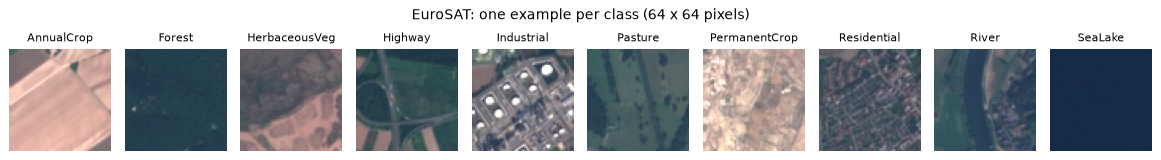

,AnnualCrop,Forest,HerbaceousVeg,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
뜻,일년생 작물(논밭),숲,초지 · 덤불,도로,산업 · 상업 건물,목초지,영년생 작물(과수원 등),주거지,하천,호수 · 바다


In [4]:
# 분류마다 학습용 20장, 평가용 10장을 무작위로 뽑습니다
N_TRAIN, N_TEST = 20, 10
rng = np.random.RandomState(0)
tr_idx, te_idx = [], []
for c in range(10):
    idx = rng.permutation(np.where(sat_y == c)[0])
    tr_idx += list(idx[:N_TRAIN]); te_idx += list(idx[N_TRAIN:N_TRAIN + N_TEST])
y_tr, y_te = sat_y[tr_idx], sat_y[te_idx]
print(f"학습용 {len(tr_idx)}장 · 평가용 {len(te_idx)}장 | 분류 10종 → 아무렇게나 찍으면 정확도 10%")
show_row([np.asarray(sat_imgs[i]) for i in tr_idx[::N_TRAIN]], CLASSES, size=1.3,
         suptitle="EuroSAT: one example per class (64 x 64 pixels)")
pd.DataFrame([KO], columns=CLASSES, index=["뜻"])

### 3-2. ViT 몸통(backbone)으로 [CLS] 벡터 꺼내기
ViT의 맨 위 분류층(`heads`, ImageNet 1,000종)을 떼어 내면 **몸통(backbone)**만 남고, ViT가 내놓는 것은 **[CLS] 토큰의 벡터**(숫자 768개)가 됩니다. 사진 1장이 숫자 768개로 요약됩니다.

In [5]:
vw = models.ViT_B_16_Weights.DEFAULT
vit = models.vit_b_16(weights=vw).eval()   # ImageNet으로 학습된 ViT-B/16 (실습 1에서 받았으면 바로, 아니면 약 0.3GB)
vit.heads = nn.Identity()                  # 맨 위 분류층 떼기 → 몸통만 남고, 출력 = [CLS] 토큰의 벡터
vit_pre = vw.transforms()                  # 64×64 사진을 224×224로 키우고 밝기 맞추기

def cls_vectors(idx, batch=50):
    """사진 번호 목록 → 사진마다 [CLS] 벡터(숫자 768개)"""
    return torch.cat([vit(torch.stack([vit_pre(sat_imgs[i]) for i in idx[k:k + batch]]))
                      for k in range(0, len(idx), batch)])

t = time.time()
Z_tr, Z_te = cls_vectors(tr_idx), cls_vectors(te_idx)
print(f"[CLS] 벡터: 학습용 {tuple(Z_tr.shape)} · 평가용 {tuple(Z_te.shape)} → 사진 1장 = 숫자 {Z_tr.shape[1]}개 | {time.time() - t:.0f}초")
print("첫 사진의 [CLS] 벡터 (앞 6개):", Z_tr[0, :6].numpy().round(2), "...")

[CLS] 벡터: 학습용 (200, 768) · 평가용 (100, 768) → 사진 1장 = 숫자 768개 | 10초
첫 사진의 [CLS] 벡터 (앞 6개): [ 0.87  1.57  1.57  0.35 -1.11  0.28] ...


### 3-3. [CLS] 벡터로 분류기 학습하고 분류해 보기
[CLS] 벡터 768개를 입력으로, 토지이용 10종을 맞히는 **로지스틱 회귀**를 학습용 200장으로 학습합니다.
ViT의 가중치는 그대로 두고 새로 정하는 것은 이 분류기의 계수뿐입니다. 이렇게 몸통은 그대로 두고 맨 위 분류기만 새로 학습하는 방법을 **linear probing**이라고 합니다.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000))   # 표준화 + 로지스틱 회귀
clf.fit(Z_tr.numpy(), y_tr)                    # 학습용 200장으로 학습 (몇 초)
pred = clf.predict(Z_te.numpy())               # 처음 보는 평가용 100장 분류
print(f"평가 정확도: {(pred == y_te).mean():.0%}  (100장 중 {(pred == y_te).sum()}장 맞힘 | 아무렇게나 찍으면 10%)")

평가 정확도: 90%  (100장 중 90장 맞힘 | 아무렇게나 찍으면 10%)


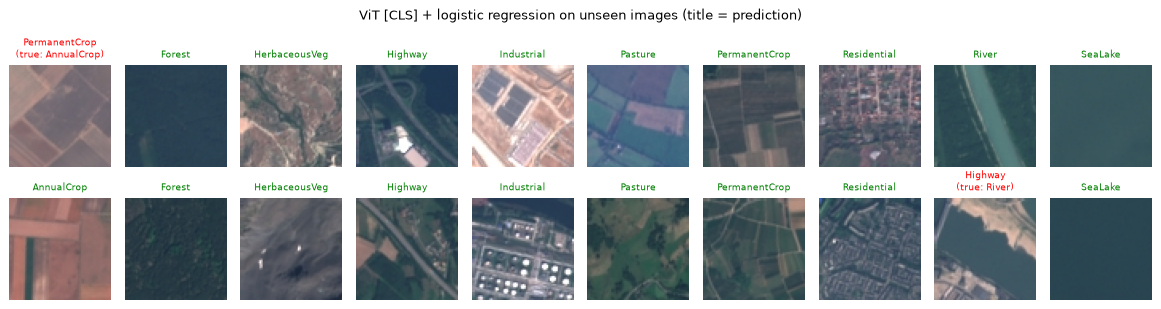

In [7]:
#@title 🎨 분류 결과 보기: 분류마다 평가용 2장 (초록 = 맞힘, 빨강 = 틀림)
show_k = [k for c in range(10) for k in np.where(y_te == c)[0][:2]]
fig, axes = plt.subplots(2, 10, figsize=(13, 3.6))
for ax, k in zip(axes.T.ravel(), show_k):
    ax.imshow(sat_imgs[te_idx[k]]); ax.axis("off")
    ok = pred[k] == y_te[k]
    ax.set_title(CLASSES[pred[k]] if ok else f"{CLASSES[pred[k]]}\n(true: {CLASSES[y_te[k]]})",
                 fontsize=7.5, color="green" if ok else "red")
fig.suptitle("ViT [CLS] + logistic regression on unseen images (title = prediction)", fontsize=10)
fig.tight_layout(); plt.show()

> ✅ **확인할 것**
> - ViT는 위성사진을 **한 장도 배운 적이 없는데**, [CLS] 벡터 위에 분류기만 새로 붙여 200장으로 학습하니 처음 보는 사진 100장 중 90장을 맞힙니다.
> - 틀린 사진은 **닮은 분류끼리** 헷갈린 경우입니다. 위 그림의 빨간 두 장도 논밭 → 과수원(영년생 작물), 하천 → 도로입니다.
> - ViT 몸통이 ImageNet(사진 128만 장)에서 배운 '사진을 보는 눈'을 빌려 쓴 덕분입니다. 통계로 말하면 [CLS] 벡터 768개 = 좋은 **설명변수**, 그 위의 분류기 = 우리가 아는 **로지스틱 회귀**입니다.
> - 실습 3의 4단계(문장 → 숫자 768개 → 로지스틱 회귀)도 같은 구조입니다. 모델 전체를 다시 학습하는 **미세조정**은 실습 4의 6단계에서 해 봅니다.
>
> ✏️ **직접 해 보기**: 3-1의 `N_TRAIN = 20`을 `5`로 바꾸고 3-1부터 다시 실행해 보세요. 분류마다 사진 5장이면 몇 %나 맞힐까요?

---
## ✨ 도전 (시간이 남으면): Gemini로 이 노트북 바꿔 보기
**파일 → Drive에 사본 저장**으로 내 사본을 만든 뒤, Colab의 **✦ Gemini**에게 말로 시켜 봅니다.
1. "2단계 Self-attention을 '민수가 지영에게 책을 빌려주었다. 그는 기뻤다.' 문장으로 다시 그려 줘"
2. "1단계 빈칸 맞히기를 통계 관련 문장 5개로 바꿔서 다시 실행해 줘"
3. "3단계를 N_TRAIN = 5, 10, 20으로 바꿔 가며 평가 정확도를 표로 비교해 줘"

> ⚠️ Gemini가 만든 코드는 **읽어 보고** 실행하세요. 결과의 해석과 숫자 확인은 사람 몫입니다.

---
## 마무리
### 오늘의 핵심
- **Transformer**: 문장 전체를 한 번에 보고 빈칸 확률 계산. Self-attention = 헤드마다 다른 가중평균
- **[CLS] 토큰 + 분류기**(linear probing): ViT 몸통은 그대로, [CLS] 벡터 768개 위에 분류기만 학습해 새 분류를 몇백 장으로 배움 (위성영상 200장으로 90%)
- 그럼 이 가중치들은 **어떻게** 정해졌을까? → **다음 시간: Loss(얼마나 틀렸나) + Optimizer(어떻게 고치나)**, 실습 3

### 국가통계와의 연결
- **Transformer** → 응답 문장 · 산업분류 (실습 3 · 4단계, 실습 4, 통계청 통계분류 자동화 2023)
- **ViT** → 위성 · 항공사진 분류 (3단계 토지이용 10종, 7교시)